# Hollow vs. solid: filling the Stanford bunny from the inside

In [Minecraft-ifying a real volcano](minecraft_mountain.ipynb) we voxelized a triangulated terrain with `voxelize_T3_H8` and discovered that the result is always a thin *shell* -- the mountain looked solid from the outside but was hollow inside. That's fine for a height field where you can just stack blocks under the surface, but it doesn't generalize to an arbitrary closed shape.

To prove the point (and to fix it), let's bring in the most famous test object in computer graphics: the Stanford bunny. This library ships it two ways -- as a closed surface (`download_bunny`) and as a solid tetrahedral volume mesh (`download_bunny(tetra=True)`). We'll voxelize both and see exactly why only one of them comes out filled.

In [1]:
from sigmaepsilon.mesh.downloads import download_bunny_coarse

mesh_surface = download_bunny_coarse(tetra=False, read=True)
leaf_surface = list(mesh_surface.cellblocks(inclusive=True, deep=True))[0]
coords_T3 = mesh_surface.coords()
topo_T3 = leaf_surface.cd.topology().to_numpy()

print(f"{coords_T3.shape[0]} points, {topo_T3.shape[0]} triangles")
print(f"surface area: {leaf_surface.area():.5f} (data units squared)")

353 points, 702 triangles
surface area: 0.05821 (data units squared)


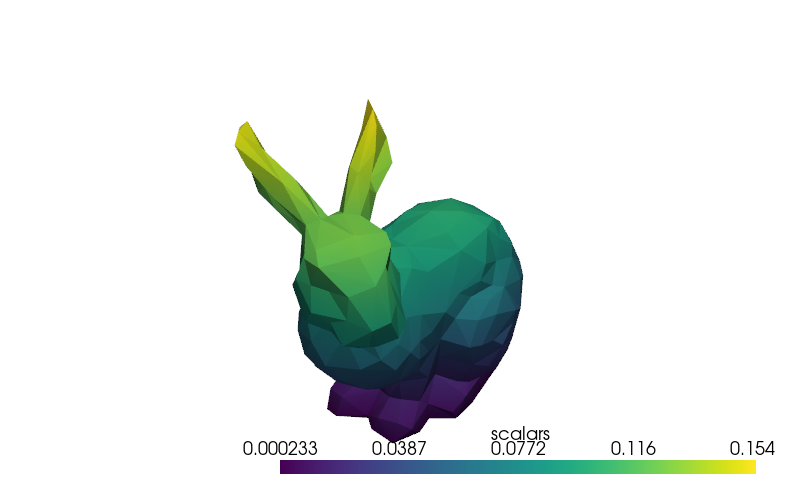

In [2]:
import pyvista as pv

pv_surface = mesh_surface.to_pv(multiblock=False, scalars=coords_T3[:, 2])[0]

plotter = pv.Plotter(notebook=True, window_size=(800, 500))
plotter.add_mesh(pv_surface, cmap="viridis", show_edges=False)
plotter.camera_position = "iso"
plotter.show(jupyter_backend="static")

## Voxelizing the surface

`voxelize_T3_H8` only ever asks one question per voxel: *does this hexahedron touch the triangulated surface?* It has no notion of "inside" -- so even though the bunny's surface is perfectly closed and watertight, the voxels it returns are just a crust wrapped around an empty cavity.

In [3]:
from sigmaepsilon.mesh.voxelize import voxelize_T3_H8
from sigmaepsilon.mesh import PolyData, PointData, CartesianFrame
from sigmaepsilon.mesh.cells import H8

frame = CartesianFrame(dim=3)
shape = (45, 45, 45)


def voxels_to_pv(coords, topo):
    pd = PointData(coords=coords, frame=frame)
    cd = H8(topo=topo, frames=frame)
    return PolyData(pd, cd).to_pv(multiblock=False, scalars=coords[:, 2])[0]


coords_shell, topo_shell = voxelize_T3_H8(coords_T3, topo_T3, shape=shape)
shell_pv = voxels_to_pv(coords_shell, topo_shell)

print(f"{topo_shell.shape[0]} voxels in the shell")

8127 voxels in the shell


## Filling it in

To genuinely fill a closed surface, the voxelizer needs a tessellation of the *interior*, not just the boundary -- a volumetric mesh. That's what `download_bunny(tetra=True)` gives us: the same bunny, but packed with TET4 cells all the way through. `voxelize_TET4_H8` then asks the same intersection question per voxel, but since tetrahedra now cover the whole volume, every voxel deep inside the bunny intersects one of them too -- the shell becomes a solid.

In [4]:
from sigmaepsilon.mesh.voxelize import voxelize_TET4_H8

mesh_solid = download_bunny_coarse(tetra=True, read=True)
leaf_solid = list(mesh_solid.cellblocks(inclusive=True, deep=True))[0]
coords_TET4 = mesh_solid.coords()
topo_TET4 = leaf_solid.cd.topology().to_numpy()

print(f"{topo_TET4.shape[0]} tetrahedra, volume {leaf_solid.volume():.6f}")

coords_solid, topo_solid = voxelize_TET4_H8(coords_TET4, topo_TET4, shape=shape)
solid_pv = voxels_to_pv(coords_solid, topo_solid)

print(f"{topo_solid.shape[0]} voxels, filled")

4663 tetrahedra, volume 0.000746


27696 voxels, filled


## Side by side

Slicing a thin slab out of both voxel grids settles the matter: one bunny is a costume, the other one has a skeleton.

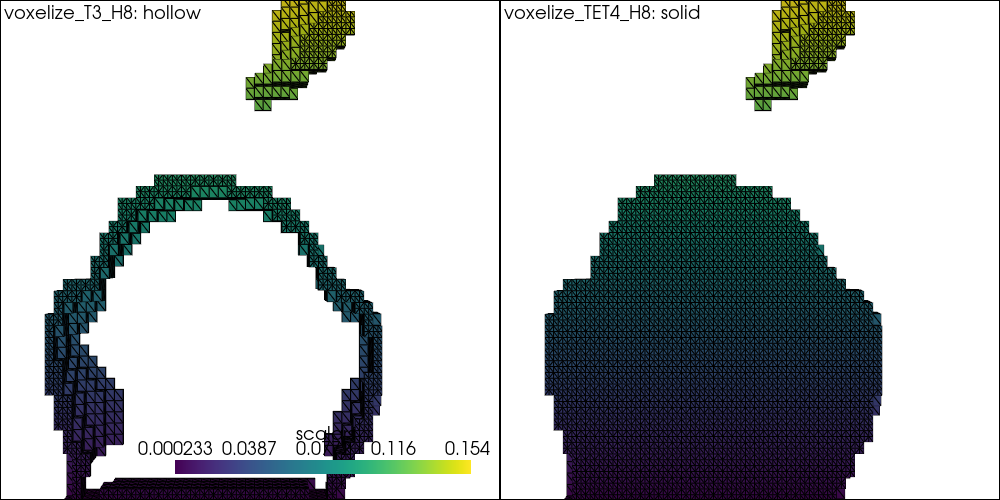

In [5]:
bounds = list(shell_pv.bounds)
mid_x = (bounds[0] + bounds[1]) / 2
res_x = (bounds[1] - bounds[0]) / shape[0]
slab = bounds.copy()
slab[0], slab[1] = mid_x - 2 * res_x, mid_x + 2 * res_x

shell_slab = shell_pv.clip_box(slab, invert=False)
solid_slab = solid_pv.clip_box(slab, invert=False)

cy = (bounds[2] + bounds[3]) / 2
cz = (bounds[4] + bounds[5]) / 2
diag = max(bounds[1] - bounds[0], bounds[3] - bounds[2], bounds[5] - bounds[4])
cam = [(mid_x - 1.8 * diag, cy, cz), (mid_x, cy, cz), (0, 0, 1)]

plotter = pv.Plotter(notebook=True, window_size=(1000, 500), shape=(1, 2))
plotter.subplot(0, 0)
plotter.add_mesh(shell_slab, cmap="viridis", show_edges=True)
plotter.add_text("voxelize_T3_H8: hollow", font_size=10)
plotter.camera_position = cam
plotter.subplot(0, 1)
plotter.add_mesh(solid_slab, cmap="viridis", show_edges=True)
plotter.add_text("voxelize_TET4_H8: solid", font_size=10)
plotter.camera_position = cam
plotter.show(jupyter_backend="static")

## The hero shot

And here's the fully filled, blocky bunny in one piece.

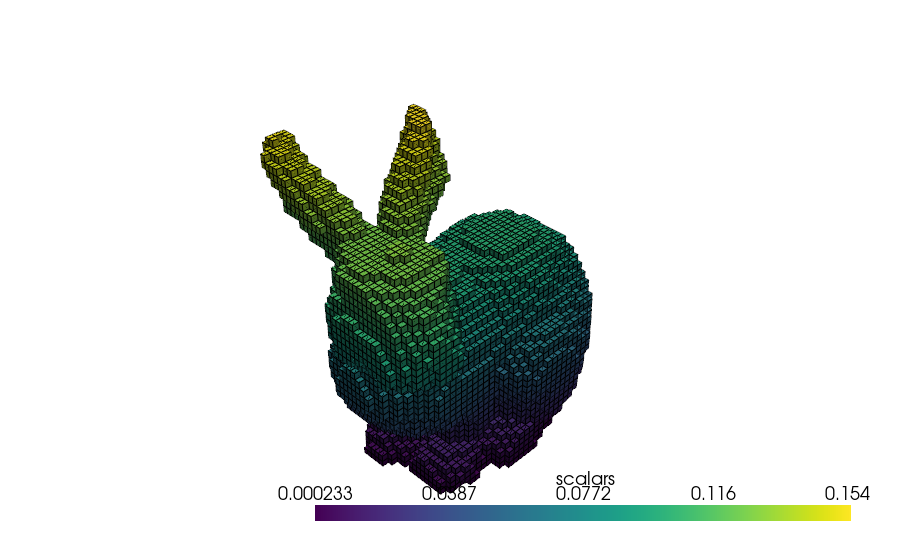

In [6]:
plotter = pv.Plotter(notebook=True, window_size=(900, 550))
plotter.add_mesh(solid_pv, cmap="viridis", show_edges=True, lighting=True)
plotter.camera_position = "iso"
plotter.show(jupyter_backend="static")

## Does the fill converge?

As with the volcano, a finer grid should bring the blocky volume closer to the true volume of the tetrahedral mesh.

In [7]:
true_volume = leaf_solid.volume()

for test_shape in [(20, 20, 20), (45, 45, 45), (70, 70, 70)]:
    c, t = voxelize_TET4_H8(coords_TET4, topo_TET4, shape=test_shape)
    pdata = PolyData(
        PointData(coords=c, frame=frame), H8(topo=t, frames=frame)
    )
    print(
        f"{test_shape}: {t.shape[0]:>6} voxels, "
        f"volume {pdata.volume():.6f} (true volume {true_volume:.6f})"
    )

(20, 20, 20):   2916 voxels, volume 0.001057 (true volume 0.000746)


(45, 45, 45):  27696 voxels, volume 0.000881 (true volume 0.000746)


(70, 70, 70):  98656 voxels, volume 0.000834 (true volume 0.000746)


## Takeaway

`voxelize_T3_H8` is the right tool when all you have -- or all you need -- is a surface, e.g. converting a 3d scan or an STL file into a thin-shelled hexahedral mesh. The moment you need the *inside* filled too, you need a volumetric tessellation first (tetrahedralize the surface with an external mesher such as `tetgen` or `gmsh`, or load one that already ships with the data, like here), and then `voxelize_TET4_H8` does the rest.